<sub>**The Annotated ML Handbook** · Part II: NumPy · by Mahir Absar Khan</sub>

# Chapter 8: NumPy arrays: shape, dtype and indexing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-2-numpy/08-numpy-arrays.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

# NumPy arrays: shape, dtype and indexing

NumPy's `ndarray` is a grid of values that all share one type, stored in a single contiguous block of memory. That design is why NumPy is fast, and why pandas, scikit-learn, TensorFlow and most of scientific Python are built on top of it. Every dataset you feed to a model eventually becomes an array.

## 8.1 Why arrays instead of lists? · *Beginner*

> **📖 Definitions**
>
> **NumPy array (ndarray)**: a grid of values that all share one type, stored in one contiguous block of memory. It can have any number of dimensions.
>
> **Vectorization**: applying an operation to a whole array at once in compiled code, instead of looping over elements in Python. Typically 10–100 times faster.

**The same computation, list vs array**

In [2]:
import numpy as np
import time

values = list(range(1_000_000))
arr = np.arange(1_000_000)

t0 = time.perf_counter()
squared_list = [v * v for v in values]
t1 = time.perf_counter()
squared_arr = arr * arr
t2 = time.perf_counter()
print(f"list: {(t1 - t0) * 1000:.1f} ms | array: {(t2 - t1) * 1000:.1f} ms | speed-up ~{(t1 - t0) / (t2 - t1):.0f}x")
print(squared_list[:5], squared_arr[:5])

list: 47.1 ms | array: 5.0 ms | speed-up ~9x
[0, 1, 4, 9, 16] [ 0  1  4  9 16]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>The universal convention: import numpy as np.</td></tr>
<tr><td><code>import time</code></td><td>Import the standard-library <code>time</code> module.</td></tr>
<tr><td><code>values = list(range(1_000_000))</code></td><td>One million Python integers in a list.</td></tr>
<tr><td><code>arr = np.arange(1_000_000)</code></td><td>The same numbers as a NumPy array.</td></tr>
<tr><td><code>t0 = time.perf_counter()</code></td><td>Start the stopwatch.</td></tr>
<tr><td><code>squared_list = [v * v for v in values]</code></td><td>Python visits each item one at a time.</td></tr>
<tr><td><code>t1 = time.perf_counter()</code></td><td>Time after the list version.</td></tr>
<tr><td><code>squared_arr = arr * arr</code></td><td>NumPy multiplies the whole array in compiled C code: <i>vectorization</i>.</td></tr>
<tr><td><code>t2 = time.perf_counter()</code></td><td>Time after the array version.</td></tr>
<tr><td><code>print(f&quot;list: {(t1 - t0) * 1000:.1f} ms | array: {(t2 - t1) * 1000:.1f} ms | speed-up ~{(t1 - t0) / (t2 - t1):.0f}x&quot;)</code></td><td>Both timings in milliseconds and how many times faster the array was.</td></tr>
<tr><td><code>print(squared_list[:5], squared_arr[:5])</code></td><td>Same numbers, very different speed.</td></tr>
</table>
</details>

> **🔑 Key idea** · **Think in whole arrays**
>
> The core NumPy skill is replacing loops over elements with operations on whole arrays. If you find yourself writing `for i in range(len(arr))`, there is almost always a vectorized alternative.

## 8.2 Creating arrays · *Beginner*

**The array factory functions**

In [3]:
a = np.array([1, 2, 3])
M = np.array([[1, 2, 3], [4, 5, 6]])
print(a, M, sep="\n")
print(np.zeros((2, 3)))
print(np.ones(4), np.full((2, 2), 7))
print(np.eye(3))
print(np.arange(0, 10, 2.5))
print(np.linspace(0, 1, 5))
print(np.empty(3).shape)

[1 2 3]
[[1 2 3]
 [4 5 6]]
[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1. 1.] [[7 7]
 [7 7]]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[0.  2.5 5.  7.5]
[0.   0.25 0.5  0.75 1.  ]
(3,)


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>a = np.array([1, 2, 3])</code></td><td>From a Python list: a 1-D array.</td></tr>
<tr><td><code>M = np.array([[1, 2, 3], [4, 5, 6]])</code></td><td>From a nested list: a 2-D array (2 rows, 3 columns).</td></tr>
<tr><td><code>print(a, M, sep=&quot;\n&quot;)</code></td><td>Print the 1-D and 2-D arrays on separate lines.</td></tr>
<tr><td><code>print(np.zeros((2, 3)))</code></td><td>Array of zeros; the shape is given as a tuple (rows, cols).</td></tr>
<tr><td><code>print(np.ones(4), np.full((2, 2), 7))</code></td><td>Ones; or any constant with <code>full</code>.</td></tr>
<tr><td><code>print(np.eye(3))</code></td><td>3x3 identity matrix.</td></tr>
<tr><td><code>print(np.arange(0, 10, 2.5))</code></td><td>Like range() but returns an array and allows float steps.</td></tr>
<tr><td><code>print(np.linspace(0, 1, 5))</code></td><td>5 evenly spaced points from 0 to 1 INCLUSIVE: perfect for plotting x-axes.</td></tr>
<tr><td><code>print(np.empty(3).shape)</code></td><td><code>empty</code> allocates without initialising (contents are garbage), so only use it when you&#x27;ll fill every value.</td></tr>
</table>
</details>

## 8.3 The three attributes you must always know · *Beginner*

> **📖 Definitions**
>
> **Shape**: a tuple giving an array's size along each dimension. *Example:* `(150, 4)` means 150 rows and 4 columns.
>
> **Dimension (ndim)**: the number of axes an array has: 1 for a vector, 2 for a table or matrix, 3 for a stack of images, and so on.
>
> **dtype**: the element type shared by all values in an array or column, such as `int64`, `float32`, `bool` or `str`.


Most NumPy (and ML) bugs are **shape bugs**. Print `.shape` constantly.

**shape, ndim, dtype, size**

In [4]:
X = np.array([[1.5, 2.0, 3.1],
              [4.0, 5.2, 6.3]])
print("shape:", X.shape)
print("ndim :", X.ndim)
print("size :", X.size)
print("dtype:", X.dtype)
print(np.array([1, 2]).dtype, np.array([True, False]).dtype, np.array(["a", "bc"]).dtype)

shape: (2, 3)
ndim : 2
size : 6
dtype: float64
int64 bool <U2


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>X = np.array([[1.5, 2.0, 3.1],</code></td><td>A 2-D array written over two lines: first row...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[4.0, 5.2, 6.3]])</code></td><td>...second row. Two rows of three floats.</td></tr>
<tr><td><code>print(&quot;shape:&quot;, X.shape)</code></td><td>(rows, columns) = (2, 3). For ML: (n_samples, n_features).</td></tr>
<tr><td><code>print(&quot;ndim :&quot;, X.ndim)</code></td><td>Number of dimensions (axes): 2.</td></tr>
<tr><td><code>print(&quot;size :&quot;, X.size)</code></td><td>Total number of elements: 6.</td></tr>
<tr><td><code>print(&quot;dtype:&quot;, X.dtype)</code></td><td>The element type shared by every value: float64.</td></tr>
<tr><td><code>print(np.array([1, 2]).dtype, np.array([True, False]).dtype, np.array([&quot;a&quot;, &quot;bc&quot;]).dtype)</code></td><td>int64, bool, Unicode string of max length 2.</td></tr>
</table>
</details>

### 8.3.1 dtypes and casting · *Intermediate*

**Choosing and converting element types**

In [5]:
x = np.array([1, 2, 3], dtype=np.float32)
print(x.dtype, x.nbytes, "bytes")
y = np.array([1.7, -2.9, 3.5]).astype(int)
print(y)
mixed = np.array([1, 2.5, "3"])
print(mixed, mixed.dtype)
small = np.array([250, 251], dtype=np.uint8)
print(small + 10)

float32 12 bytes
[ 1 -2  3]
['1' '2.5' '3'] <U32
[4 5]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>x = np.array([1, 2, 3], dtype=np.float32)</code></td><td>Set the dtype explicitly. float32 halves memory vs float64; deep learning uses it by default.</td></tr>
<tr><td><code>print(x.dtype, x.nbytes, &quot;bytes&quot;)</code></td><td>3 values x 4 bytes = 12 bytes.</td></tr>
<tr><td><code>y = np.array([1.7, -2.9, 3.5]).astype(int)</code></td><td><code>astype</code> returns a converted COPY. Float -&gt; int truncates toward zero.</td></tr>
<tr><td><code>print(y)</code></td><td>Display the value of <code>y</code>.</td></tr>
<tr><td><code>mixed = np.array([1, 2.5, &quot;3&quot;])</code></td><td>Mixed types are upcast to a common type, here strings!</td></tr>
<tr><td><code>print(mixed, mixed.dtype)</code></td><td>A classic source of &quot;why can&#x27;t I do maths on my column?&quot;</td></tr>
<tr><td><code>small = np.array([250, 251], dtype=np.uint8)</code></td><td>uint8: 0..255, the standard type for image pixels.</td></tr>
<tr><td><code>print(small + 10)</code></td><td>Integer overflow WRAPS AROUND silently: 260 -&gt; 4.</td></tr>
</table>
</details>

> **🐞 Bug hunt** · **Image maths gives weird numbers**
>
> Pixel arrays are often `uint8`, and arithmetic on them silently wraps around past 255. Convert first: `img = img.astype(np.float32) / 255.0`.

## 8.4 Reshaping · *Beginner*

**reshape, flatten, transpose, new axes**

In [6]:
a = np.arange(12)
B = a.reshape(3, 4)
print(B)
print(a.reshape(2, -1).shape)
print(B.T.shape)
print(B.ravel())
v = np.array([1, 2, 3])
print(v.shape, v[:, np.newaxis].shape, v[np.newaxis, :].shape)
print(v.reshape(-1, 1).shape)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2, 6)
(4, 3)
[ 0  1  2  3  4  5  6  7  8  9 10 11]
(3,) (3, 1) (1, 3)
(3, 1)


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>a = np.arange(12)</code></td><td>0..11, shape (12,).</td></tr>
<tr><td><code>B = a.reshape(3, 4)</code></td><td>Reinterpret as 3 rows x 4 columns. Total size must match (3*4 = 12).</td></tr>
<tr><td><code>print(B)</code></td><td>Display the value of <code>B</code>.</td></tr>
<tr><td><code>print(a.reshape(2, -1).shape)</code></td><td>-1 means &quot;work this dimension out for me&quot;: (2, 6).</td></tr>
<tr><td><code>print(B.T.shape)</code></td><td><code>.T</code> transposes: rows become columns, giving (4, 3).</td></tr>
<tr><td><code>print(B.ravel())</code></td><td>Flatten back to 1-D (returns a view when possible).</td></tr>
<tr><td><code>v = np.array([1, 2, 3])</code></td><td>A 1-D array of shape (3,).</td></tr>
<tr><td><code>print(v.shape, v[:, np.newaxis].shape, v[np.newaxis, :].shape)</code></td><td>Add an axis: column vector (3,1) or row vector (1,3).</td></tr>
<tr><td><code>print(v.reshape(-1, 1).shape)</code></td><td>The same column vector: the shape scikit-learn wants for ONE feature.</td></tr>
</table>
</details>

**Sizes must match**

⚠️ *This cell raises an error **on purpose**, so you can see the real message.*

In [7]:
np.arange(10).reshape(3, 4)

ValueError: cannot reshape array of size 10 into shape (3,4)

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>np.arange(10).reshape(3, 4)</code></td><td>10 elements cannot fill a 3x4 (=12) grid.</td></tr>
</table>
</details>

> **🐞 Bug hunt** · **scikit-learn: `Expected 2D array, got 1D array instead`**
>
> Models expect `X` with shape `(n_samples, n_features)`. A single feature stored as shape `(n,)` must become `(n, 1)`: use `x.reshape(-1, 1)`, or select it from a DataFrame as `df[["col"]]` (double brackets).

## 8.5 Indexing and slicing · *Beginner*

**Indexing 1-D and 2-D arrays**

In [8]:
A = np.arange(1, 13).reshape(3, 4)
print(A)
print(A[0, 2])
print(A[1])
print(A[:, 1])
print(A[0:2, 1:3])
print(A[-1, ::-1])
print(A[:, [0, 3]])

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
3
[5 6 7 8]
[ 2  6 10]
[[2 3]
 [6 7]]
[12 11 10  9]
[[ 1  4]
 [ 5  8]
 [ 9 12]]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>A = np.arange(1, 13).reshape(3, 4)</code></td><td>[[1..4], [5..8], [9..12]]</td></tr>
<tr><td><code>print(A)</code></td><td>Display the value of <code>A</code>.</td></tr>
<tr><td><code>print(A[0, 2])</code></td><td>Row 0, column 2 -&gt; 3. (Use one bracket with a comma, not A[0][2].)</td></tr>
<tr><td><code>print(A[1])</code></td><td>A whole row: [5 6 7 8].</td></tr>
<tr><td><code>print(A[:, 1])</code></td><td>A whole column: every row (:), column 1 -&gt; [2 6 10].</td></tr>
<tr><td><code>print(A[0:2, 1:3])</code></td><td>Rows 0-1, columns 1-2: a 2x2 block.</td></tr>
<tr><td><code>print(A[-1, ::-1])</code></td><td>Last row, reversed.</td></tr>
<tr><td><code>print(A[:, [0, 3]])</code></td><td><i>Fancy indexing</i>: a list of column indices picks columns 0 and 3.</td></tr>
</table>
</details>

### 8.5.1 Boolean masks: the most useful trick in NumPy · *Beginner*

> **📖 Definitions**
>
> **Boolean mask**: an array of `True`/`False` values of the same shape as the data, used to select the positions where it is `True`.
>
> **Fancy indexing**: selecting elements with a list or array of indices, such as `a[[0, 3, 5]]`. It always returns a copy.


A comparison on an array produces an array of True/False. Using that as an index selects only the True positions.

**Filtering with boolean masks**

In [9]:
temps = np.array([18.5, 22.1, 30.4, 15.0, 27.8, 33.2])
mask = temps > 25
print(mask)
print(temps[mask])
print(temps[(temps > 20) & (temps < 30)])
print(mask.sum(), mask.mean())
temps[temps < 16] = 16
print(temps)
print(np.where(temps > 25, "hot", "ok"))
print(np.flatnonzero(temps > 25))

[False False  True False  True  True]
[30.4 27.8 33.2]
[22.1 27.8]
3 0.5
[18.5 22.1 30.4 16.  27.8 33.2]
['ok' 'ok' 'hot' 'ok' 'hot' 'hot']
[2 4 5]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>temps = np.array([18.5, 22.1, 30.4, 15.0, 27.8, 33.2])</code></td><td>Six daily temperatures.</td></tr>
<tr><td><code>mask = temps &gt; 25</code></td><td>Element-wise comparison -&gt; boolean array.</td></tr>
<tr><td><code>print(mask)</code></td><td>Display the value of <code>mask</code>.</td></tr>
<tr><td><code>print(temps[mask])</code></td><td>Keep only the values where the mask is True.</td></tr>
<tr><td><code>print(temps[(temps &gt; 20) &amp; (temps &lt; 30)])</code></td><td>Combine with &amp; (and), | (or), ~ (not). Parentheses are REQUIRED.</td></tr>
<tr><td><code>print(mask.sum(), mask.mean())</code></td><td>True counts as 1: the number and the fraction of hot days.</td></tr>
<tr><td><code>temps[temps &lt; 16] = 16</code></td><td>Assign through a mask: clip low values in place.</td></tr>
<tr><td><code>print(temps)</code></td><td>Display the value of <code>temps</code>.</td></tr>
<tr><td><code>print(np.where(temps &gt; 25, &quot;hot&quot;, &quot;ok&quot;))</code></td><td><code>np.where(cond, a, b)</code>: element-wise if/else.</td></tr>
<tr><td><code>print(np.flatnonzero(temps &gt; 25))</code></td><td>The INDICES where the condition holds.</td></tr>
</table>
</details>

> **⚠️ Pitfall** · **Use `&` and `|`, not `and` / `or`, on arrays**
>
> `(a > 1) and (a < 5)` raises `ValueError: The truth value of an array with more than one element is ambiguous`. Python's `and` wants a single True/False. Use the element-wise operators `&`, `|`, `~` and wrap each comparison in parentheses.

## 8.6 Views vs copies · *Intermediate*

> **📖 Definitions**
>
> **View**: a new array object that looks at the same memory as another array. Changing a view changes the original.


Basic slicing returns a **view**: a window onto the same memory. Changing the view changes the original. Fancy indexing and boolean masks return **copies**.

**When does modifying a slice change the original?**

In [10]:
a = np.arange(6)
s = a[1:4]
s[0] = 100
print(a)
c = a[1:4].copy()
c[0] = -1
print(a, c)
f = a[[0, 1]]
f[0] = 999
print(a[0], np.shares_memory(a, s), np.shares_memory(a, f))

[  0 100   2   3   4   5]
[  0 100   2   3   4   5] [-1  2  3]
0 True False


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>a = np.arange(6)</code></td><td>[0 1 2 3 4 5]</td></tr>
<tr><td><code>s = a[1:4]</code></td><td>A view: no data copied.</td></tr>
<tr><td><code>s[0] = 100</code></td><td>Writing into the view...</td></tr>
<tr><td><code>print(a)</code></td><td>...changes <code>a</code> as well.</td></tr>
<tr><td><code>c = a[1:4].copy()</code></td><td>Explicit copy: independent data.</td></tr>
<tr><td><code>c[0] = -1</code></td><td>Change the copy.</td></tr>
<tr><td><code>print(a, c)</code></td><td><code>a</code> is unaffected by changes to <code>c</code>.</td></tr>
<tr><td><code>f = a[[0, 1]]</code></td><td>Fancy indexing always makes a copy.</td></tr>
<tr><td><code>f[0] = 999</code></td><td>Change the fancy-indexed copy; <code>a</code> is untouched.</td></tr>
<tr><td><code>print(a[0], np.shares_memory(a, s), np.shares_memory(a, f))</code></td><td><code>shares_memory</code> tells you whether two arrays overlap.</td></tr>
</table>
</details>

## 8.7 Combining and splitting arrays · *Intermediate*

**Stacking and splitting**

In [11]:
x = np.array([[1, 2], [3, 4]])
y = np.array([[5, 6]])
print(np.concatenate([x, y], axis=0))
print(np.vstack([x, y]))
print(np.hstack([x, x]))
print(np.column_stack([[1, 2, 3], [4, 5, 6]]))
print(np.stack([x, x]).shape)
top, bottom = np.split(np.arange(8), 2)
print(top, bottom)

[[1 2]
 [3 4]
 [5 6]]
[[1 2]
 [3 4]
 [5 6]]
[[1 2 1 2]
 [3 4 3 4]]
[[1 4]
 [2 5]
 [3 6]]
(2, 2, 2)
[0 1 2 3] [4 5 6 7]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>x = np.array([[1, 2], [3, 4]])</code></td><td>A 2x2 array.</td></tr>
<tr><td><code>y = np.array([[5, 6]])</code></td><td>A 1x2 array (one row).</td></tr>
<tr><td><code>print(np.concatenate([x, y], axis=0))</code></td><td>Join along rows (axis 0). Other dimensions must match.</td></tr>
<tr><td><code>print(np.vstack([x, y]))</code></td><td>Same as above: vertical stack.</td></tr>
<tr><td><code>print(np.hstack([x, x]))</code></td><td>Side by side (axis 1).</td></tr>
<tr><td><code>print(np.column_stack([[1, 2, 3], [4, 5, 6]]))</code></td><td>Turn 1-D arrays into columns of a 2-D array: building a feature matrix.</td></tr>
<tr><td><code>print(np.stack([x, x]).shape)</code></td><td><code>stack</code> adds a NEW axis: two (2,2) arrays -&gt; (2, 2, 2).</td></tr>
<tr><td><code>top, bottom = np.split(np.arange(8), 2)</code></td><td>Split into equal parts.</td></tr>
<tr><td><code>print(top, bottom)</code></td><td>[0 1 2 3] and [4 5 6 7].</td></tr>
</table>
</details>

## 8.8 Understanding axes · *Beginner*

> **📖 Definitions**
>
> **Axis**: one dimension of an array. In a 2-D array, `axis=0` runs down the rows and `axis=1` runs across the columns. Aggregating along an axis collapses it.


`axis=0` means "operate down the rows" (collapsing them, so you get one result per column). `axis=1` means "operate across columns" (one result per row).

**Aggregating along an axis**

In [12]:
scores = np.array([[70, 80, 90],
                   [60, 65, 70],
                   [95, 85, 75]])
print(scores.sum())
print(scores.mean(axis=0))
print(scores.mean(axis=1))
print(scores.max(axis=1), scores.argmax(axis=1))
print(scores.mean(axis=0, keepdims=True).shape)

690
[75.         76.66666667 78.33333333]
[80. 65. 85.]
[90 70 95] [2 2 0]
(1, 3)


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>scores = np.array([[70, 80, 90],</code></td><td>3 students (rows) x 3 exams (columns).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[60, 65, 70],</code></td><td>Student 2.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[95, 85, 75]])</code></td><td>Student 3; the closing brackets end the array.</td></tr>
<tr><td><code>print(scores.sum())</code></td><td>No axis: everything collapses to one number.</td></tr>
<tr><td><code>print(scores.mean(axis=0))</code></td><td>Mean of each COLUMN (each exam), averaged over students.</td></tr>
<tr><td><code>print(scores.mean(axis=1))</code></td><td>Mean of each ROW (each student), averaged over exams.</td></tr>
<tr><td><code>print(scores.max(axis=1), scores.argmax(axis=1))</code></td><td>Best score per student and WHICH exam it was in.</td></tr>
<tr><td><code>print(scores.mean(axis=0, keepdims=True).shape)</code></td><td>keepdims keeps the collapsed axis with length 1: (1, 3). Handy for broadcasting.</td></tr>
</table>
</details>

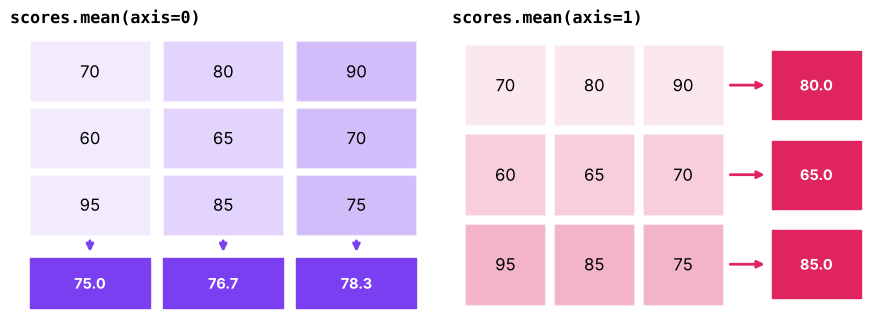

In [13]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
data = np.array([[70, 80, 90], [60, 65, 70], [95, 85, 75]])
for ax, axis, title, col in [(axes[0], 0, "scores.mean(axis=0)", "#7b3ff2"), (axes[1], 1, "scores.mean(axis=1)", "#e0245e")]:
    ax.set_xlim(-0.6, 4.2 if axis == 1 else 2.6); ax.set_ylim(-1.7 if axis == 0 else -0.6, 2.6); ax.axis("off")
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", family="monospace")
    means = data.mean(axis=axis)
    for i in range(3):
        for j in range(3):
            k = j if axis == 0 else i
            ax.add_patch(plt.Rectangle((j - 0.45, 2 - i - 0.45), 0.9, 0.9, color=col, alpha=0.10 + 0.12 * k, ec="white"))
            ax.text(j, 2 - i, data[i, j], ha="center", va="center", fontsize=12)
    if axis == 0:
        for j in range(3):
            ax.annotate("", xy=(j, -0.75), xytext=(j, -0.5), arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
            ax.add_patch(plt.Rectangle((j - 0.45, -1.55), 0.9, 0.75, color=col))
            ax.text(j, -1.18, f"{means[j]:.1f}", ha="center", va="center", color="white", fontweight="bold")
    else:
        for i in range(3):
            ax.annotate("", xy=(2.95, 2 - i), xytext=(2.5, 2 - i), arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
            ax.add_patch(plt.Rectangle((3.0, 2 - i - 0.38), 1.0, 0.76, color=col))
            ax.text(3.5, 2 - i, f"{means[i]:.1f}", ha="center", va="center", color="white", fontweight="bold")
plt.tight_layout(); plt.show()

> **✍️ Try it yourself**
>
> 1. Create a 5x5 array of the numbers 1–25 and extract its centre 3x3 block.
> 2. From `x = np.random.default_rng(0).normal(size=1000)`, compute the fraction of values more than 2 standard deviations from the mean (expect about 0.05).
> 3. Reshape `np.arange(24)` into shape `(2, 3, 4)` and compute the sum along each axis. Predict each result's shape first.
>
> *Worked solutions:* [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 8*.

---

⬅️ [Chapter 7: The Pythonic toolkit](../part-1-python/07-python-toolkit.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 9: Computing with NumPy: vectorization, broadcasting, statistics, linear algebra](09-numpy-compute.ipynb) ➡️